# 02 — Who leaves, and which customers are worth the effort

**Inputs:** `data/processed/customers.csv` and the frozen split from notebook 01. **Training rows only**: 6,000 customers. Validation and test are never read here.

**Outputs:** `segments_train.csv` and `eda_summary.json` (unchanged sealed aggregates), plus three business views added after the first review — `age_bands_train.csv`, `profiles_train.csv` and `business_context_train.json`.

**Scope:** every proportion below is a retrospective association measured on undated records. No proportion is an annual churn rate, and no segment is shown to *cause* departure. Section titles name what a retention team can act on; the modelling questions close the notebook.

In [1]:
from pathlib import Path
import json, hashlib, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown
ROOT = Path.cwd() if (Path.cwd() / 'brief.md').exists() else Path.cwd().parent
assert (ROOT / 'brief.md').exists(), 'Run from the project root or notebooks/'
sys.path.insert(0, str(ROOT / 'src'))
from presentation import display, en, segment_rate_figure
SEED = 42
OUT = ROOT / 'data/results'
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.figsize': (9, 5), 'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})
def sha(path): return hashlib.sha256(Path(path).read_bytes()).hexdigest()

In [2]:
contract = json.loads((ROOT / 'data/processed/contract.json').read_text())
assert sha(ROOT / 'data/raw/Churn_Modelling.csv') == contract['raw_sha256']
assert sha(ROOT / 'data/processed/splits.csv') == contract['split_sha256']
base = pd.read_csv(ROOT / 'data/processed/customers.csv')
splits = pd.read_csv(ROOT / 'data/processed/splits.csv')
assert base.observation_id.is_unique and splits.observation_id.is_unique
train = base.merge(splits.query("split == 'train'"), on='observation_id', validate='one_to_one').drop(columns='split')
assert len(train) == 6000
# Retain only training rows in analytical memory.
del base, splits
numeric = ['CreditScore','Age','Tenure','Balance','NumOfProducts','EstimatedSalary']
display(train[numeric].describe().T.rename(columns={'count':'n','mean':'moyenne','std':'écart-type','min':'minimum','max':'maximum'}).round(2))
print(f'Training: {len(train):,} customers; {train.Exited.sum():,} departure labels; proportion {train.Exited.mean():.2%}.')

Training: 6,000 customers; 1,222 departure labels; proportion 20.37%.


,n,Mean,Standard deviation,Minimum,25%,50%,75%,Maximum
CreditScore,6000.0,650.81,96.44,350.00,584.00,652.00,717.00,850.00
Age,6000.0,38.91,10.45,18.00,32.00,37.00,44.00,92.00
Tenure,6000.0,5.02,2.89,0.00,3.00,5.00,8.00,10.00
Balance,6000.0,76153.35,62396.11,0.00,0.00,96656.25,127842.60,221532.80
NumOfProducts,6000.0,1.54,0.59,1.00,1.00,1.00,2.00,4.00
EstimatedSalary,6000.0,99535.24,57389.21,11.58,50226.18,98630.60,148441.07,199970.74


## Feature distributions

Age and tenure are expressed in years under the documented interpretation. Balance and salary remain in the file's monetary units, with **unknown currency**. A balance is never treated as a margin. Histograms count all training customers, including rare profiles and zero balances.

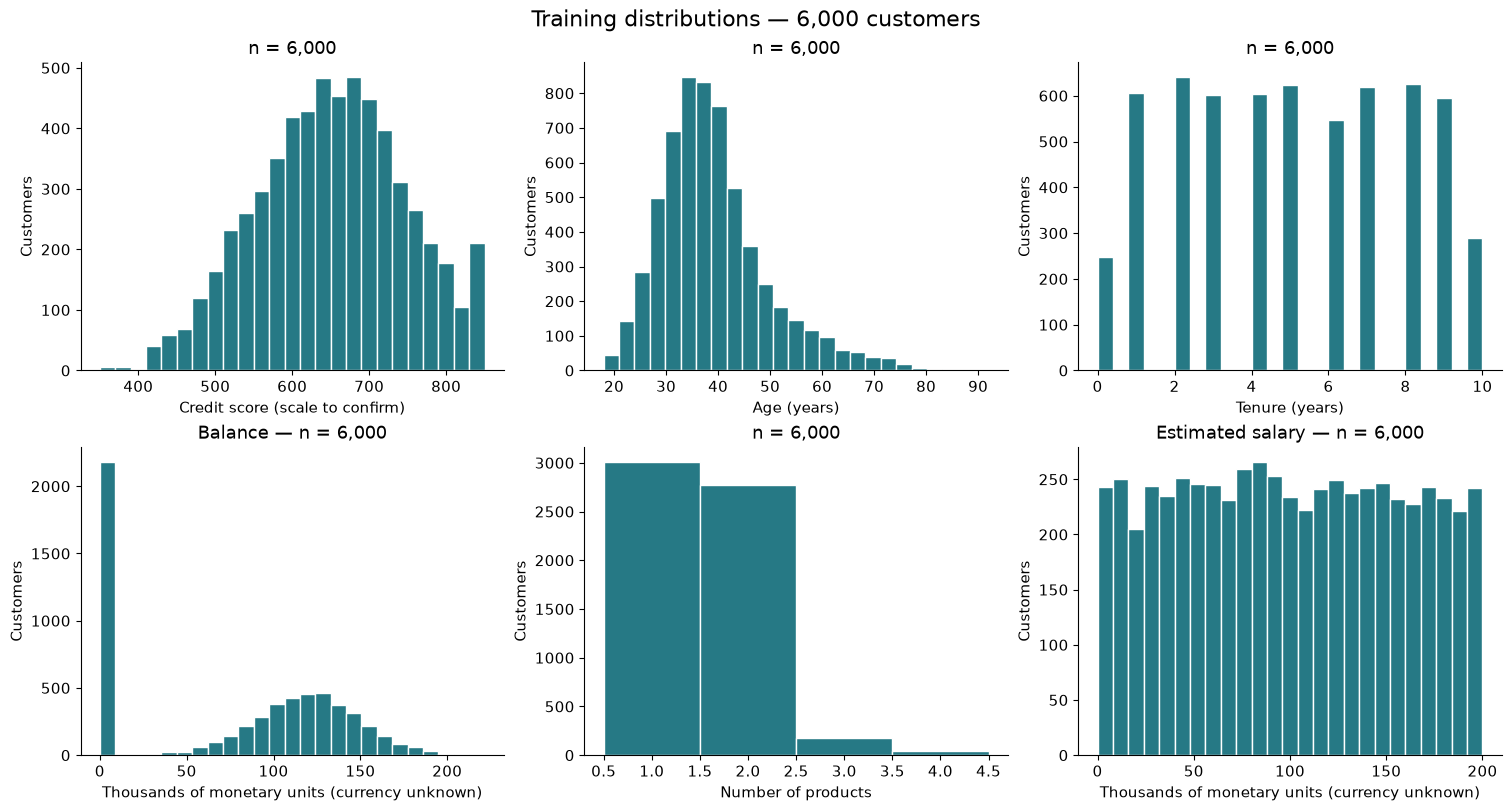

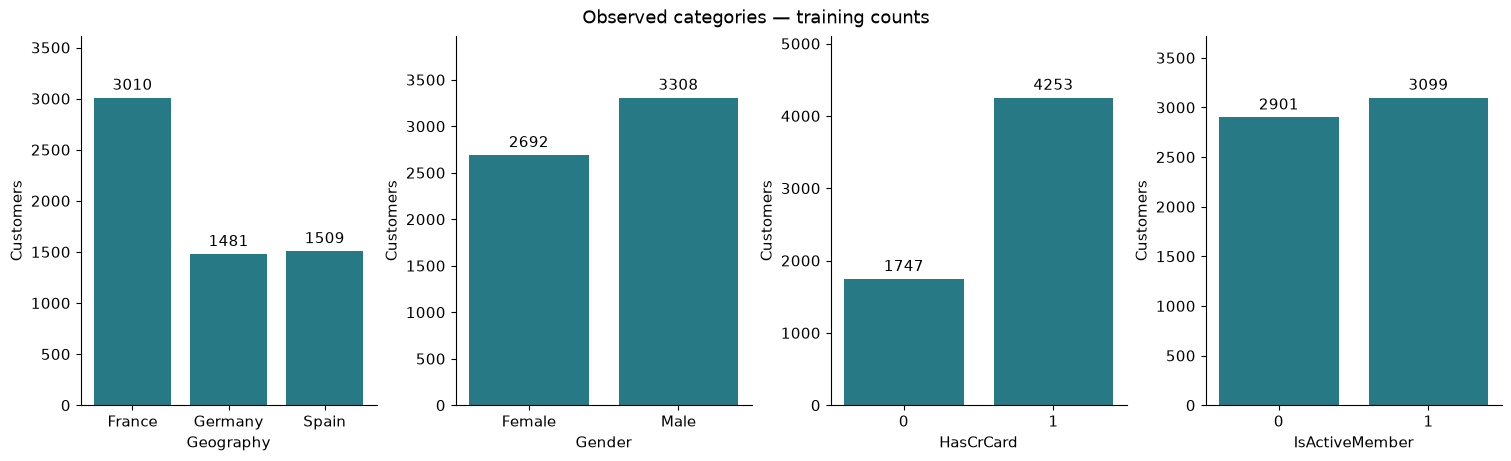

In [3]:
labels = {'CreditScore':'Credit score (scale to confirm)','Age':'Age (years)','Tenure':'Tenure (years)','Balance':'Balance (unknown monetary unit)','NumOfProducts':'Number of products','EstimatedSalary':'Estimated salary (unknown monetary unit)'}
fig, axes = plt.subplots(2,3,figsize=(15,8),layout='constrained')
for ax,col in zip(axes.flat,numeric):
 bins = np.arange(.5,5.5) if col == 'NumOfProducts' else 25
 ax.hist(train[col], bins=bins, color='#267985', edgecolor='white')
 ax.set(xlabel=labels[col], ylabel='Customers', title=f'n = {train[col].notna().sum():,}')
 if col in ['Balance','EstimatedSalary']:
  ax.xaxis.set_major_locator(plt.matplotlib.ticker.MaxNLocator(5))
  ax.xaxis.set_major_formatter(plt.matplotlib.ticker.FuncFormatter(lambda value, pos: f'{value/1000:g}'))
  ax.set_xlabel('Thousands of monetary units (currency unknown)')
  ax.set_title(('Balance' if col == 'Balance' else 'Estimated salary') + f' — n = {len(train):,}')
fig.suptitle('Training distributions — 6,000 customers', fontsize=16)
plt.show()
fig, axes = plt.subplots(1,4,figsize=(15,4.5),layout='constrained')
for ax,col in zip(axes,['Geography','Gender','HasCrCard','IsActiveMember']):
 counts=train[col].value_counts().sort_index()
 bars=ax.bar(counts.index.astype(str),counts.values,color='#267985')
 ax.bar_label(bars, padding=3)
 ax.set(xlabel=col,ylabel='Customers',ylim=(0,counts.max()*1.2))
fig.suptitle('Observed categories — training counts')
plt.show()

## How much churn, and in which groups

Across the 6,000 training customers, 20.4% carry a departure label. The proportions below are unadjusted: each one mixes its own factor with everything correlated with it, and they are not adjusted for multiple comparisons. Group sizes and 95% Wilson intervals are shown so that a high proportion measured on a handful of customers is not read as a strong signal.

,Variable,Segment,n,Churn labels,Churn proportion,95% CI lower,95% CI upper
0,Geography,France,3010,486,16.1%,14.9%,17.5%
1,Geography,Germany,1481,481,32.5%,30.1%,34.9%
2,Geography,Spain,1509,255,16.9%,15.1%,18.9%
3,Gender,Female,2692,669,24.9%,23.3%,26.5%
4,Gender,Male,3308,553,16.7%,15.5%,18.0%
5,IsActiveMember,0,2901,765,26.4%,24.8%,28.0%
6,IsActiveMember,1,3099,457,14.7%,13.5%,16.0%
7,NumOfProducts,1,3012,822,27.3%,25.7%,28.9%
8,NumOfProducts,2,2777,220,7.9%,7.0%,9.0%
9,NumOfProducts,3,172,141,82.0%,75.6%,87.0%


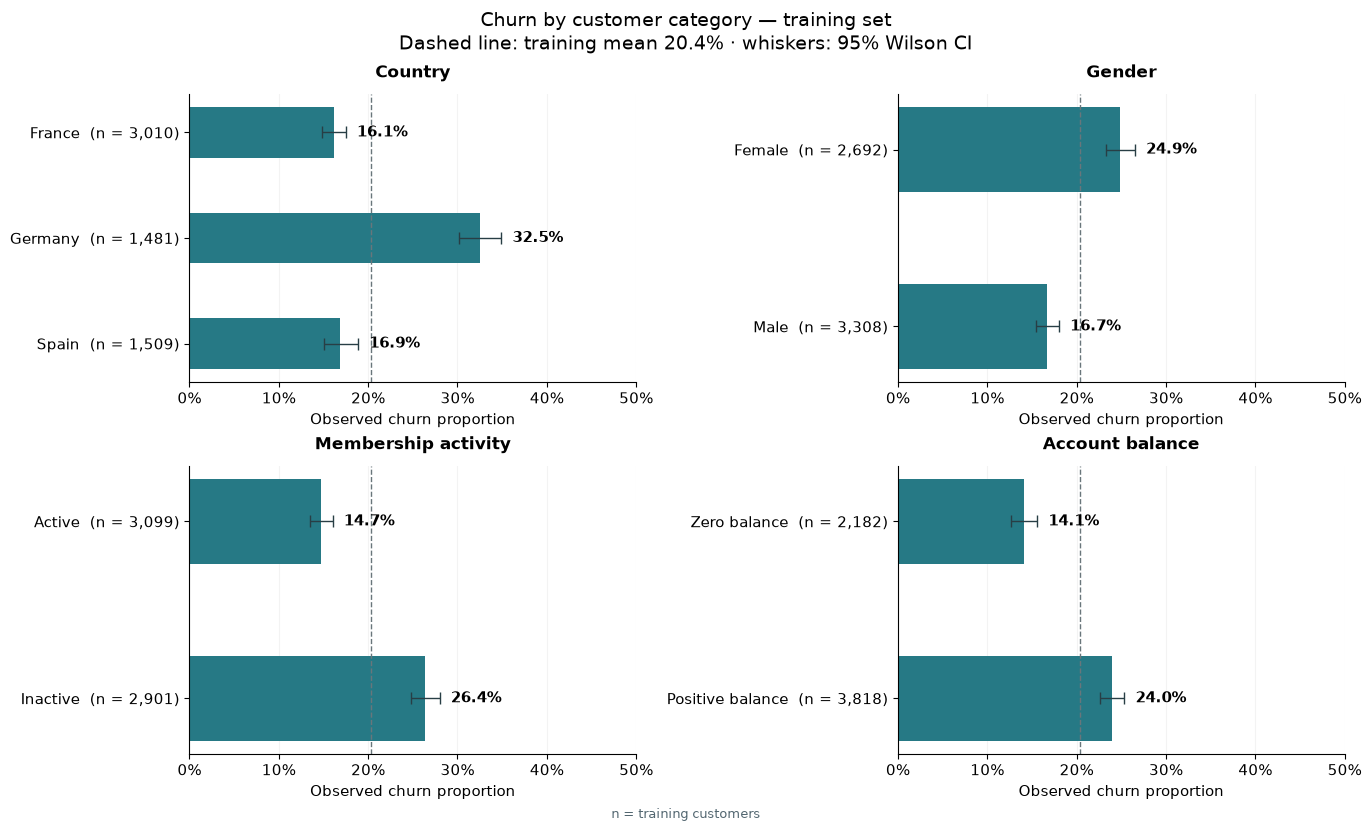

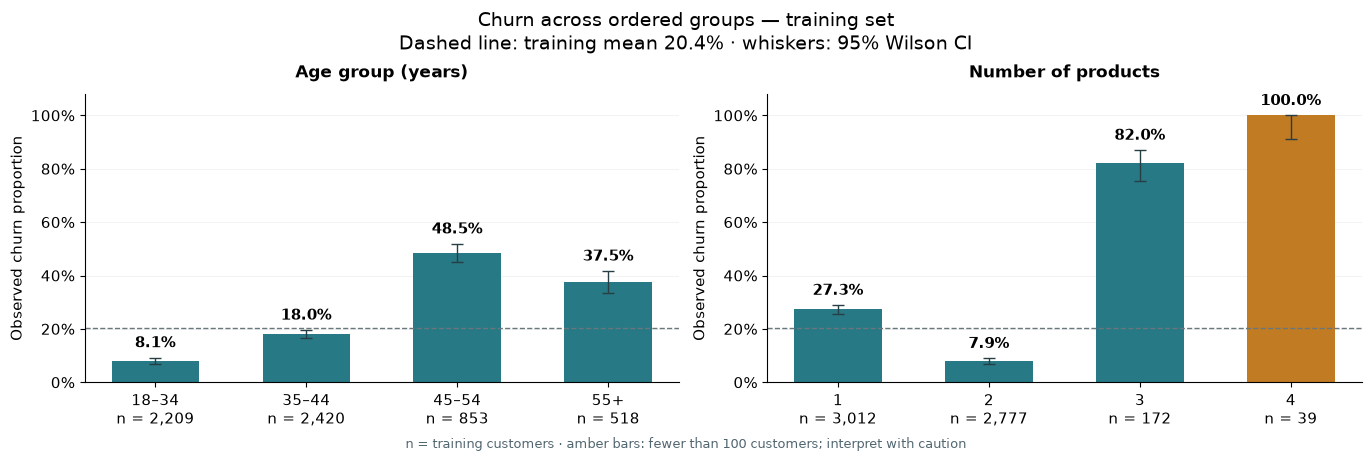

In [4]:
def wilson(k,n):
    z=1.959963984540054
    p=np.asarray(k)/np.asarray(n)
    den=1+z*z/np.asarray(n)
    center=(p+z*z/(2*np.asarray(n)))/den
    half=z*np.sqrt(p*(1-p)/np.asarray(n)+z*z/(4*np.asarray(n)**2))/den
    return center-half,center+half
train['AgeBand'] = pd.cut(train.Age,[17,34,44,54,np.inf],labels=['18–34','35–44','45–54','55+'])
train['ZeroBalance'] = np.where(train.Balance.eq(0),'Solde nul','Solde positif')
parts=[]
for col in ['Geography','Gender','IsActiveMember','NumOfProducts','AgeBand','ZeroBalance']:
    s=train.groupby(col,observed=True).Exited.agg(n='size',departs='sum').reset_index().rename(columns={col:'segment'})
    s['variable']=col
    s['segment']=s.segment.astype(str)
    s['proportion']=s.departs/s.n
    s['ic95_bas'],s['ic95_haut']=wilson(s.departs,s.n)
    parts.append(s)
segments=pd.concat(parts,ignore_index=True)[['variable','segment','n','departs','proportion','ic95_bas','ic95_haut']]
display(segments.style.format({'proportion':'{:.1%}','ic95_bas':'{:.1%}','ic95_haut':'{:.1%}'}))

segment_rate_figure(
    segments, ['Geography', 'Gender', 'IsActiveMember', 'ZeroBalance'],
    train.Exited.mean(), title='Churn by customer category — training set',
)
plt.show()
segment_rate_figure(
    segments, ['AgeBand', 'NumOfProducts'], train.Exited.mean(),
    title='Churn across ordered groups — training set',
)
plt.show()

## Who leaves: five customer profiles

Variable-by-variable proportions answer "which group churns most". A retention team also needs "who are these customers, how many are they, and what share of all departures do they carry". The five overlapping profiles below are built from the factors above; because they overlap, their shares do not add up to 100%.

Two refinements come with them. The age band `55+` mixes two populations and is split into `55–64` and `65+`. The zero-balance gap is examined by country, because the zero-balance group is not distributed evenly across the three markets.

Leavers hold 24.2% of training balances while making up 20.4% of customers.
Zero balance: 9.9 points of gap overall, 4.5 points outside Germany.


,Variable,Segment,n,Churn labels,Churn proportion,95% CI lower,95% CI upper
0,AgeBandFine,18–34,2209,178,8.1%,7.0%,9.3%
1,AgeBandFine,35–44,2420,436,18.0%,16.5%,19.6%
2,AgeBandFine,45–54,853,414,48.5%,45.2%,51.9%
3,AgeBandFine,55–64,345,173,50.1%,44.9%,55.4%
4,AgeBandFine,65+,173,21,12.1%,8.1%,17.8%


,Profile,n,Churn labels,Churn proportion,Share of all departures,Mean balance,95% CI lower,95% CI upper
0,"45–64, inactive",555,373,67.2%,30.5%,"84,418",63.2%,71.0%
1,"Germany, single product",783,333,42.5%,27.3%,"119,852",39.1%,46.0%
2,"Under 45, single product, inactive",1119,261,23.3%,21.4%,"100,960",20.9%,25.9%
3,Three or four products,211,180,85.3%,14.7%,"77,318",79.9%,89.5%
4,"Two products, active",1472,89,6.0%,7.3%,"51,762",4.9%,7.4%


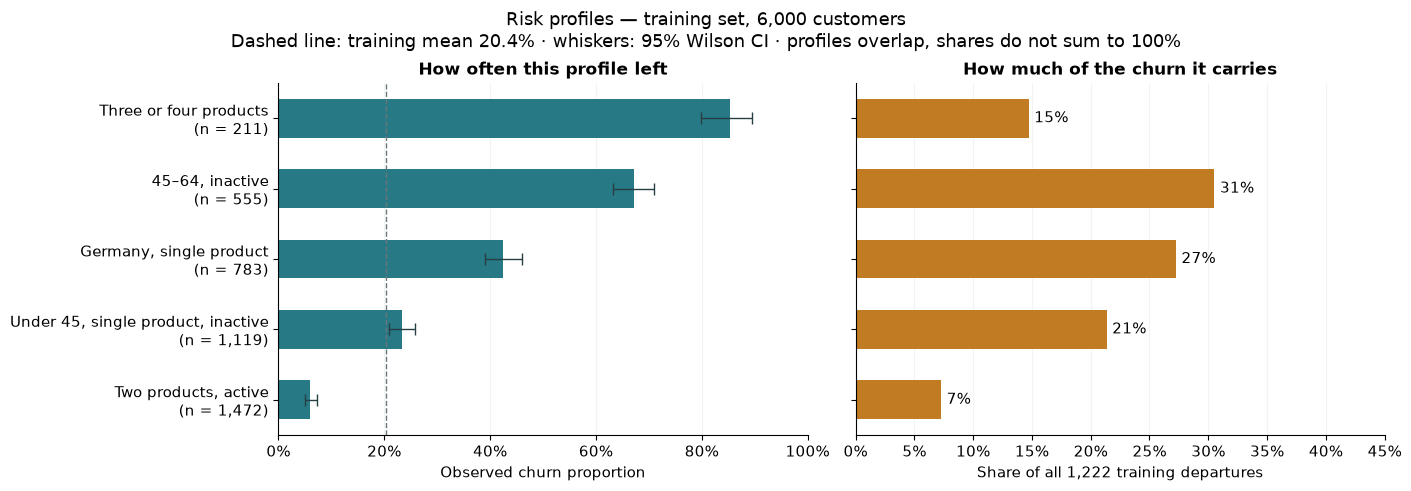

,Age band,Active member,n,Churn labels,Churn proportion
0,18–34,0,1076,110,10.2%
1,18–34,1,1133,68,6.0%
2,35–44,0,1251,272,21.7%
3,35–44,1,1169,164,14.0%
4,45–54,0,432,260,60.2%
5,45–54,1,421,154,36.6%
6,55–64,0,123,113,91.9%
7,55–64,1,222,60,27.0%
8,65+,0,19,10,52.6%
9,65+,1,154,11,7.1%


In [5]:
# Business views added after the first review: finer age bands, overlapping risk
# profiles, customer value and two cross-tabulations. Training rows only; the target,
# the split and the sealed aggregates written below are unchanged.
bands = pd.cut(train.Age, [17, 34, 44, 54, 64, np.inf], labels=['18–34', '35–44', '45–54', '55–64', '65+'])
age_fine = train.groupby(bands, observed=True).Exited.agg(n='size', departs='sum').reset_index()
age_fine.columns = ['segment', 'n', 'departs']
age_fine['variable'] = 'AgeBandFine'
age_fine['segment'] = age_fine.segment.astype(str)
age_fine['proportion'] = age_fine.departs / age_fine.n
age_fine['ic95_bas'], age_fine['ic95_haut'] = wilson(age_fine.departs, age_fine.n)
age_fine = age_fine[['variable', 'segment', 'n', 'departs', 'proportion', 'ic95_bas', 'ic95_haut']]
display(age_fine.style.format({'proportion': '{:.1%}', 'ic95_bas': '{:.1%}', 'ic95_haut': '{:.1%}'}))

definitions = {
    '45–64, inactive': train.Age.between(45, 64) & train.IsActiveMember.eq(0),
    'Germany, single product': train.Geography.eq('Germany') & train.NumOfProducts.eq(1),
    'Under 45, single product, inactive': train.Age.lt(45) & train.NumOfProducts.eq(1) & train.IsActiveMember.eq(0),
    'Three or four products': train.NumOfProducts.ge(3),
    'Two products, active': train.NumOfProducts.eq(2) & train.IsActiveMember.eq(1),
}
rows = []
for name, mask in definitions.items():
    part = train[mask]
    low, high = wilson(int(part.Exited.sum()), len(part))
    rows.append({'profil': name, 'n': len(part), 'departs': int(part.Exited.sum()),
                 'proportion': float(part.Exited.mean()), 'part_des_departs': float(part.Exited.sum() / train.Exited.sum()),
                 'solde_moyen': float(part.Balance.mean()), 'ic95_bas': float(low), 'ic95_haut': float(high)})
profiles = pd.DataFrame(rows)
display(profiles.style.format({'proportion': '{:.1%}', 'part_des_departs': '{:.1%}',
                               'solde_moyen': '{:,.0f}', 'ic95_bas': '{:.1%}', 'ic95_haut': '{:.1%}'}))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), layout='constrained')
order = profiles.sort_values('proportion')
positions = np.arange(len(order))
axes[0].barh(positions, order.proportion, height=.55, color=['#267985'] * len(order),
             xerr=[order.proportion - order.ic95_bas, order.ic95_haut - order.proportion],
             capsize=4, error_kw={'ecolor': '#283e45', 'elinewidth': 1})
axes[0].axvline(train.Exited.mean(), color='#69767b', linestyle='--', linewidth=1)
axes[0].set_yticks(positions, [f'{r.profil}\n(n = {r.n:,})' for r in order.itertuples()])
axes[0].xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
axes[0].set(xlim=(0, 1), xlabel='Observed churn proportion')
axes[0].set_title('How often this profile left', fontsize=12, fontweight='bold')
bars = axes[1].barh(positions, order.part_des_departs, height=.55, color='#c17b22')
axes[1].bar_label(bars, labels=[f'{v:.0%}' for v in order.part_des_departs], padding=4, fontsize=11)
axes[1].set_yticks(positions, [''] * len(order))
axes[1].xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
axes[1].set(xlim=(0, .45), xlabel='Share of all 1,222 training departures')
axes[1].set_title('How much of the churn it carries', fontsize=12, fontweight='bold')
for ax in axes:
    ax.grid(axis='x', alpha=.15)
    ax.set_axisbelow(True)
fig.suptitle('Risk profiles — training set, 6,000 customers\nDashed line: training mean 20.4% · whiskers: 95% Wilson CI · profiles overlap, shares do not sum to 100%', fontsize=13)
plt.show()

# Customer value: departures are not concentrated in low-balance customers.
leavers, stayers = train[train.Exited.eq(1)], train[train.Exited.eq(0)]
value = {'part_encours_detenue_par_partants': float(leavers.Balance.sum() / train.Balance.sum()),
         'part_clients_partants': float(train.Exited.mean()),
         'solde_moyen_partants': float(leavers.Balance.mean()),
         'solde_moyen_restants': float(stayers.Balance.mean())}
# Zero balance by country: the group is absent from one market, so the gap is partly compositional.
zero = train.Balance.eq(0)
outside = train.Geography.ne('Germany')
zero_context = {'clients_solde_nul': int(zero.sum()),
                'solde_nul_par_pays': {k: int(v) for k, v in train.loc[zero, 'Geography'].value_counts().items()},
                'ecart_global_points': float(100 * (train.loc[~zero, 'Exited'].mean() - train.loc[zero, 'Exited'].mean())),
                'ecart_hors_allemagne_points': float(100 * (train.loc[outside & ~zero, 'Exited'].mean() - train.loc[outside & zero, 'Exited'].mean()))}
cross = train.groupby([bands, 'IsActiveMember'], observed=True).Exited.agg(n='size', departs='sum').reset_index()
cross.columns = ['tranche_age', 'actif', 'n', 'departs']
cross['proportion'] = cross.departs / cross.n
display(cross.style.format({'proportion': '{:.1%}'}))
products = train.groupby('NumOfProducts').Exited.agg(n='size', departs='sum')
context = {'valeur': value, 'solde_nul': zero_context,
           'produits': {str(i): {'n': int(r.n), 'departs': int(r.departs), 'proportion': float(r.departs / r.n)}
                        for i, r in products.iterrows()},
           'croise_age_activite': cross.to_dict(orient='records'),
           'portee': 'associations rétrospectives sur train ; profils chevauchants ; aucune causalité établie'}
age_fine.to_csv(OUT / 'age_bands_train.csv', index=False)
profiles.to_csv(OUT / 'profiles_train.csv', index=False)
(OUT / 'business_context_train.json').write_text(json.dumps(context, ensure_ascii=False, indent=2))
print(f"Leavers hold {value['part_encours_detenue_par_partants']:.1%} of training balances while making up {value['part_clients_partants']:.1%} of customers.")
print(f"Zero balance: {zero_context['ecart_global_points']:.1f} points of gap overall, {zero_context['ecart_hors_allemagne_points']:.1f} points outside Germany.")

In [6]:
def row(var,label):
 return segments.loc[segments.variable.eq(var)&segments.segment.eq(str(label))].iloc[0]
inactive,active=row('IsActiveMember',0),row('IsActiveMember',1)
products=segments.query("variable == 'NumOfProducts'")
top=profiles.sort_values('part_des_departs',ascending=False).iloc[0]
text = f"""## What a retention team can take from this

- **Churn is concentrated in recognisable profiles.** The largest one, {top.profil.lower()} customers, is {top.n:,} customers with a {top.proportion:.0%} departure proportion and carries {top.part_des_departs:.0%} of all {int(train.Exited.sum()):,} training departures. A high proportion on a small group matters less than a moderate one on a large group: the four-product group churns at 100% but accounts for 3% of departures.
- **The customers who leave are not the cheap ones.** Leavers hold {value['part_encours_detenue_par_partants']:.0%} of training balances while making up {value['part_clients_partants']:.0%} of customers, and the two highest-risk profiles hold the largest average balances. What is at stake is not only a count of customers.
- **Age peaks between 45 and 64, and retired customers are stable.** Splitting the old `55+` band gives {age_fine.set_index('segment').loc['55–64','proportion']:.0%} for 55–64 against {age_fine.set_index('segment').loc['65+','proportion']:.0%} for 65 and over (n={int(age_fine.set_index('segment').loc['65+','n']):,}). Reporting a single `55+` figure hides that reversal.
- **Activity remains the clearest single lever to investigate**: {inactive.proportion:.1%} of departure labels among inactive customers (n={inactive.n:,}) versus {active.proportion:.1%} among active ones (n={active.n:,}). It is an association; raising activity has no demonstrated causal effect here.
- **The zero-balance gap is largely a country effect.** No German customer has a zero balance, and outside Germany the gap narrows from {zero_context['ecart_global_points']:.1f} to {zero_context['ecart_hors_allemagne_points']:.1f} points. It should not be presented as an unexplained finding.
- **Product count must not be forced into a linear effect**: proportions run from {products.proportion.min():.1%} to {products.proportion.max():.1%}, with a smallest group of {products.n.min():,} customers.

**Questions for 03:** does a tree model capture these nonlinearities better than logistic regression? Which variables actually carry the score, and who does it target? Does ranking concentrate departures at identical contact capacity, and by how much against a rule a manager could apply by hand? Gender is described but excluded from predictors to avoid direct targeting by that characteristic; this does not guarantee the absence of indirect bias. Feature timing, especially activity and products, must be confirmed before any campaign.

**Handoff:** `segments_train.csv` and `eda_summary.json` carry the sealed training aggregates; `age_bands_train.csv`, `profiles_train.csv` and `business_context_train.json` carry the business views. No individual prediction or record is published.
"""
display(Markdown(text))
segments.to_csv(OUT/'segments_train.csv',index=False)
summary={'n_train':len(train),'positive_train':int(train.Exited.sum()),'prevalence_train':float(train.Exited.mean()),'zero_balance_train':int(train.Balance.eq(0).sum()),'source_split_sha256':contract['split_sha256'],'scope':'associations rétrospectives sur train ; horizon inconnu'}
(OUT/'eda_summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2))

## What a retention team can take from this

- **Churn is concentrated in recognisable profiles.** The largest one, 45–64, inactive customers, is 555 customers with a 67% departure proportion and carries 31% of all 1,222 training departures. A high proportion on a small group matters less than a moderate one on a large group: the four-product group churns at 100% but accounts for 3% of departures.
- **The customers who leave are not the cheap ones.** Leavers hold 24% of training balances while making up 20% of customers, and the two highest-risk profiles hold the largest average balances. What is at stake is not only a count of customers.
- **Age peaks between 45 and 64, and retired customers are stable.** Splitting the old `55+` band gives 50% for 55–64 against 12% for 65 and over (n=173). Reporting a single `55+` figure hides that reversal.
- **Activity remains the clearest single lever to investigate**: 26.4% of departure labels among inactive customers (n=2,901) versus 14.7% among active ones (n=3,099). It is an association; raising activity has no demonstrated causal effect here.
- **The zero-balance gap is largely a country effect.** No German customer has a zero balance, and outside Germany the gap narrows from 9.9 to 4.5 points. It should not be presented as an unexplained finding.
- **Product count must not be forced into a linear effect**: proportions run from 7.9% to 100.0%, with a smallest group of 39 customers.

**Questions for 03:** does a tree model capture these nonlinearities better than logistic regression? Which variables actually carry the score, and who does it target? Does ranking concentrate departures at identical contact capacity, and by how much against a rule a manager could apply by hand? Gender is described but excluded from predictors to avoid direct targeting by that characteristic; this does not guarantee the absence of indirect bias. Feature timing, especially activity and products, must be confirmed before any campaign.

**Handoff:** `segments_train.csv` and `eda_summary.json` carry the sealed training aggregates; `age_bands_train.csv`, `profiles_train.csv` and `business_context_train.json` carry the business views. No individual prediction or record is published.
